# 10c · Custo de servir por cliente e por SKU
**Pergunta:** quais clientes e quais produtos **pagam a operação** e quais dão prejuízo depois que o custo
do CD é descontado da margem?

**Contribuição = margem bruta − custo de servir.**
- **Margem bruta** = unidades × (preço − custo do produto), do cadastro de SKUs (estimativa).
- **Custo de servir** = o custo do CD da Fase 8 (R$ 96,7 mi/ano), levado até cada linha de pedido pelo
  direcionador de cada atividade:

| Atividade | Primeiro vai para... | Direcionador |
|---|---|---|
| Separação | linha de pedido (canal × zona) | nº de linhas |
| Embalagem e expedição | linha de pedido | linhas (e-commerce) ou palete-equivalente (B2B) |
| Devoluções | linha devolvida | nº de devoluções |
| Aluguel, energia, estrutura, inventário cíclico | SKU | palete-dia em estoque |
| Capital em estoque | SKU | valor médio em estoque |
| Recebimento | SKU | paletes recebidos |
| Reabastecimento | SKU | reabastecimentos |
| Perdas | SKU | baixas do **próprio** SKU (direto, sem rateio) |
| Indiretos | linha | proporcional à mão de obra direta já atribuída |

O custo que fica no SKU passa para as linhas pelas **unidades expedidas** do SKU. SKUs sem venda no ano
(estoque parado) não têm linha: o custo deles aparece à parte, para o total fechar.

**Escala:** os dados têm 10% dos clientes e SKUs, e cada um representa um cliente ou SKU real. Por isso os
valores **por cliente e por SKU** estão em R$/ano sem multiplicar; os **totais** são × 10. Frete de
entrega e impostos ficam fora (como na Fase 8). Perdas de frio nas duas visões (dados e mercado).

*EN summary: activity-based cost-to-serve by customer and SKU (gross margin minus DC cost), whale curve,
e-commerce minimum-order break-even and loss-making SKUs, in both cold-loss views.*

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dcanalysis import q, save, savefig, log, params, ROOT

NB = "10c"
PH8, PH10 = ROOT / "reports" / "phase8", ROOT / "reports" / "phase10"
P = params()
INI, FIM = P["costs"]["base_year"]
K = P["flow_simulation"]["scale_factor"]
ZONAS = ["dry", "chilled", "frozen"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

# Custos da Fase 8 por canal x zona, levados para a escala dos dados (÷ 10)
cts = pd.read_csv(PH8 / "08a_custo_servir_canal_zona.csv", sep=";", decimal=",").set_index(["channel", "zone"]) / K
frio = pd.read_csv(PH10 / "10a_perdas_frio_visoes.csv", sep=";", decimal=",").set_index("zona")
print(f"Custo do CD a distribuir: R$ {cts.total.sum() * K / 1e6:,.1f} mi/ano (escala cheia)")

Custo do CD a distribuir: R$ 96.7 mi/ano (escala cheia)


## 1. Linhas de pedido do ano-base e direcionadores por SKU

In [2]:
lin = q("""SELECT f.order_line_id, f.order_id, f.customer_id, f.sku_id, f.channel, s.zone,
                  f.qty_picked_units AS und, f.qty_picked_units * s.unit_price AS receita,
                  f.qty_picked_units * (s.unit_price - s.unit_cost) AS margem,
                  1.0 * f.qty_picked_units / (s.units_per_case * s.cases_per_pallet) AS pal_eq
           FROM fact_order_line f JOIN dim_sku s ON s.sku_id = f.sku_id
           WHERE f.order_date >= :i AND f.order_date < :f""", i=INI, f=FIM)
dev = q("""SELECT order_line_id, COUNT(*) AS n_dev FROM fact_return
           WHERE return_date >= :i AND return_date < :f GROUP BY 1""", i=INI, f=FIM)
lin = lin.merge(dev, on="order_line_id", how="left").fillna({"n_dev": 0})

sku = q("SELECT sku_id, sku_code, description, category, zone, status, unit_cost FROM dim_sku").set_index("sku_id")
sku["palete_dias"] = q("""SELECT sku_id, SUM(n_pallets) AS v FROM fact_inventory_daily
                          WHERE date_key >= :i AND date_key < :f GROUP BY 1""", i=INI, f=FIM).set_index("sku_id").v
sku["valor_estoque"] = q("""SELECT i.sku_id, SUM(i.qty_units * s.unit_cost) AS v FROM fact_inventory_daily i
                            JOIN dim_sku s ON s.sku_id = i.sku_id WHERE i.date_key >= :i AND i.date_key < :f
                            GROUP BY 1""", i=INI, f=FIM).set_index("sku_id").v
sku["paletes_rec"] = q("""SELECT sku_id, COUNT(*) AS v FROM fact_receipt WHERE arrival_ts >= :i AND arrival_ts < :f
                          GROUP BY 1""", i=INI, f=FIM).set_index("sku_id").v
sku["reab"] = q("""SELECT sku_id, COUNT(*) AS v FROM fact_movement WHERE movement_type = 'REPLENISH'
                   AND date_key >= :i AND date_key < :f GROUP BY 1""", i=INI, f=FIM).set_index("sku_id").v
baixas = q("""SELECT m.sku_id, m.movement_type = 'WRITE_OFF_COLD_CHAIN' AS frio, SUM(m.qty_units * s.unit_cost) AS v
              FROM fact_movement m JOIN dim_sku s ON s.sku_id = m.sku_id
              WHERE m.movement_type LIKE 'WRITE_OFF_%' AND m.date_key >= :i AND m.date_key < :f
              GROUP BY 1, 2""", i=INI, f=FIM).pivot_table(index="sku_id", columns="frio", values="v", aggfunc="sum")
sku["perda_frio"] = baixas.get(1)
sku["perda_outras"] = baixas.get(0)
sku = sku.fillna({c: 0 for c in ["palete_dias", "valor_estoque", "paletes_rec", "reab", "perda_frio", "perda_outras"]})
sku["und_exp"] = lin.groupby("sku_id").und.sum()
sku["und_exp"] = sku.und_exp.fillna(0)
print(f"{len(lin):,} linhas no ano-base | {lin.customer_id.nunique():,} clientes | "
      f"{(sku.und_exp > 0).sum()} SKUs com venda e {(sku.und_exp == 0).sum()} sem venda")

779,547 linhas no ano-base | 3,150 clientes | 583 SKUs com venda e 17 sem venda


## 2. Custo por SKU (atividades de armazém e perdas)
O total de cada atividade **por zona** é o da Fase 8; dentro da zona ele é dividido entre os SKUs pelo
direcionador. As perdas entram direto, pelas baixas de cada SKU.

In [3]:
zona_tot = cts.groupby(level="zone").sum()

def ratear(atividade, direcionador):
    """Divide o custo da atividade de cada zona entre os SKUs da zona, proporcional ao direcionador."""
    peso = sku[direcionador] / sku.groupby("zone")[direcionador].transform("sum")
    return peso.fillna(0) * sku.zone.map(zona_tot[atividade])

for ativ, drv in [("aluguel", "palete_dias"), ("energia", "palete_dias"), ("estrutura", "palete_dias"),
                  ("inventario_ciclico", "palete_dias"), ("capital_estoque", "valor_estoque"),
                  ("recebimento", "paletes_rec"), ("reabastecimento", "reab")]:
    sku[f"c_{ativ}"] = ratear(ativ, drv)
# Perdas: baixas reais do SKU. Na visão de mercado, a perda por FRIO é reduzida pelo fator da zona (10a).
fator = frio["fator_ajuste"].reindex(ZONAS).fillna(1.0)
sku["c_perdas"] = sku.perda_frio + sku.perda_outras
sku["c_perdas_mercado"] = sku.perda_frio * sku.zone.map(fator) + sku.perda_outras
assert abs(sku.c_perdas.sum() - zona_tot.perdas.sum()) / zona_tot.perdas.sum() < 0.001, "perdas por SKU devem fechar com a Fase 8"
COL_SKU = [c for c in sku.columns if c.startswith("c_") and c != "c_perdas_mercado"]
sku["custo_sku"] = sku[COL_SKU].sum(axis=1)
sku["custo_sku_mercado"] = sku.custo_sku - sku.c_perdas + sku.c_perdas_mercado
MO_SKU = ["c_recebimento", "c_reabastecimento", "c_inventario_ciclico"]            # mão de obra direta no SKU

## 3. Custo de cada linha de pedido

In [4]:
cz = ["channel", "zone"]
def por_linha(atividade, peso):
    """Divide o custo da atividade de cada canal x zona entre as linhas, proporcional ao peso."""
    w = peso / peso.groupby([lin.channel, lin.zone]).transform("sum")
    pool = lin[cz].merge(cts[atividade].reset_index(), on=cz, how="left")[atividade].values   # custo do canal x zona da linha
    return w.fillna(0) * pool

lin["c_separacao"] = por_linha("separacao", pd.Series(1.0, index=lin.index))
peso_exp = np.where(lin.channel == "ECOM", 1.0, lin.pal_eq)
lin["c_expedicao"] = por_linha("embalagem_expedicao", pd.Series(peso_exp, index=lin.index))
lin["c_devolucao"] = por_linha("devolucoes", lin.n_dev)
# Custo do SKU por unidade expedida -> linha
taxa = (sku.custo_sku / sku.und_exp).replace(np.inf, 0)
taxa_m = (sku.custo_sku_mercado / sku.und_exp).replace(np.inf, 0)
taxa_mo = (sku[MO_SKU].sum(axis=1) / sku.und_exp).replace(np.inf, 0)
lin["c_sku"] = lin.und * lin.sku_id.map(taxa)
lin["c_sku_mercado"] = lin.und * lin.sku_id.map(taxa_m)
# Indiretos: proporcionais à mão de obra direta da linha (separação + expedição + devolução + MO do SKU)
mo = lin.c_separacao + lin.c_expedicao + lin.c_devolucao + lin.und * lin.sku_id.map(taxa_mo)
lin["c_indiretos"] = cts.indiretos.sum() * mo / mo.sum()
base_cols = ["c_separacao", "c_expedicao", "c_devolucao", "c_indiretos"]
lin["custo"] = lin[base_cols + ["c_sku"]].sum(axis=1)
lin["custo_mercado"] = lin[base_cols + ["c_sku_mercado"]].sum(axis=1)

sem_venda = sku.loc[sku.und_exp == 0, "custo_sku"].sum()
fecha = (lin.custo.sum() + sem_venda) * K
print(f"Conferência: linhas R$ {lin.custo.sum() * K / 1e6:,.2f} mi + SKUs sem venda R$ {sem_venda * K / 1e6:,.2f} mi "
      f"= R$ {fecha / 1e6:,.2f} mi (Fase 8: R$ {cts.total.sum() * K / 1e6:,.2f} mi)")
assert abs(fecha - cts.total.sum() * K) / (cts.total.sum() * K) < 0.001, "o custo de servir precisa fechar com a Fase 8"

Conferência: linhas R$ 96.11 mi + SKUs sem venda R$ 0.55 mi = R$ 96.66 mi (Fase 8: R$ 96.66 mi)


## 4. Rentabilidade por cliente

In [5]:
cli = q("SELECT customer_id, customer_code, channel, region FROM dim_customer").set_index("customer_id")
g = lin.groupby("customer_id").agg(pedidos=("order_id", "nunique"), linhas=("order_line_id", "size"), und=("und", "sum"),
                                   receita=("receita", "sum"), margem=("margem", "sum"),
                                   custo=("custo", "sum"), custo_mercado=("custo_mercado", "sum"))
cli = cli.join(g, how="inner")
cli["contrib"] = cli.margem - cli.custo
cli["contrib_mercado"] = cli.margem - cli.custo_mercado
cli["custo_pct_receita"] = 100 * cli.custo / cli.receita
save(cli.reset_index().round(2), "10c_rentabilidade_cliente", out=PH10)

res_cli = cli.groupby("channel").agg(clientes=("pedidos", "size"), receita=("receita", "sum"), margem=("margem", "sum"),
                                     custo=("custo", "sum"), contrib=("contrib", "sum"), contrib_m=("contrib_mercado", "sum"))
res_cli["neg_dados_%"] = cli.groupby("channel").contrib.apply(lambda s: 100 * (s < 0).mean())
res_cli["neg_mercado_%"] = cli.groupby("channel").contrib_mercado.apply(lambda s: 100 * (s < 0).mean())
for c in ["receita", "margem", "custo", "contrib", "contrib_m"]:
    res_cli[c] = res_cli[c] * K / 1e6                 # totais em escala cheia (R$ mi/ano)
res_cli.round(1)

,clientes,receita,margem,custo,contrib,contrib_m,neg_dados_%,neg_mercado_%
channel,,,,,,,,
B2B,150,"2,739.40",827.70,92.20,735.50,777.60,0.00,0.00
ECOM,3000,22.90,6.90,3.90,3.00,3.30,0.00,0.00


In [6]:
# Margem do cadastro: preço / custo de cada SKU (checagem de qualidade antes de concluir sobre rentabilidade)
markup = q("SELECT zone, unit_price / unit_cost AS markup FROM dim_sku WHERE unit_cost > 0")
print("Preço ÷ custo por SKU:", markup.markup.describe()[["min", "50%", "max"]].round(2).to_dict())
dist = cli.groupby("channel").custo_pct_receita.describe(percentiles=[0.1, 0.5, 0.9])[["min", "10%", "50%", "90%", "max"]]
dist.round(2)

Preço ÷ custo por SKU: {'min': 1.25, '50%': 1.42, 'max': 1.6}


,min,10%,50%,90%,max
channel,,,,,
B2B,3.08,3.25,3.37,3.47,3.57
ECOM,10.85,14.71,17.01,19.84,27.53


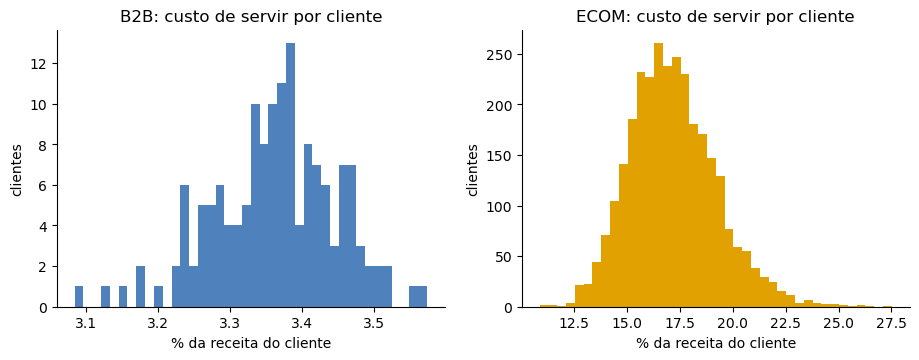

In [7]:
# Histograma por canal: distribuição do custo de servir em % da receita de cada cliente
# (mostra a dispersão entre clientes, que é o que diferencia quem custa caro).
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, canal, cor in zip(axes, ["B2B", "ECOM"], ["#4F81BD", "#E1A100"]):
    ax.hist(cli.loc[cli.channel == canal, "custo_pct_receita"], bins=40, color=cor)
    ax.set_title(f"{canal}: custo de servir por cliente"); ax.set_xlabel("% da receita do cliente"); ax.set_ylabel("clientes")
savefig(fig, "10c_custo_servir_clientes", out=PH10)

**Leitura (com aviso de qualidade dos dados):**
- O preço do cadastro é **1,2 a 1,6 vez o custo** em todos os SKUs, uma margem bruta de ~30% da receita.
  O custo do CD é ~3,5% da receita. Com essa margem, **nenhum cliente tem contribuição negativa** só com o
  custo do CD. Em uma empresa real, frete, comercial e impostos também entram e a conclusão pode mudar.
- As **lojas B2B são quase idênticas** no custo de servir (3,1% a 3,6% da receita). Isso é uma limitação do
  gerador, que não diferencia perfil de loja (tamanho, mix, frequência). Com dados reais, é aqui que
  aparecem os clientes caros.
- No **e-commerce** a dispersão é real: o custo vai de ~11% a ~28% da receita do cliente, e depende do
  **tamanho do pedido** (seção 5).

## 5. E-commerce: quanto um pedido precisa ter para pagar o custo
O custo de um pedido de e-commerce é quase fixo (viagem de separação + embalagem), e a margem cresce com o
tamanho. Por faixa de valor do pedido, comparamos margem e custo de servir para achar o **ponto de equilíbrio**.

In [8]:
ped = (lin[lin.channel == "ECOM"].groupby("order_id")
       .agg(receita=("receita", "sum"), margem=("margem", "sum"), custo=("custo", "sum"), custo_m=("custo_mercado", "sum"),
            linhas=("order_line_id", "size")))
faixas = [0, 25, 50, 75, 100, 150, 250, np.inf]
ped["faixa"] = pd.cut(ped.receita, faixas, right=False,
                      labels=["< 25", "25–50", "50–75", "75–100", "100–150", "150–250", "≥ 250"])
fx = ped.groupby("faixa", observed=True).agg(pedidos=("receita", "size"), receita_media=("receita", "mean"),
                                             margem_media=("margem", "mean"), custo_medio=("custo", "mean"),
                                             linhas_medias=("linhas", "mean"))
fx["contrib_media"] = fx.margem_media - fx.custo_medio
fx["pct_pedidos"] = 100 * fx.pedidos / fx.pedidos.sum()
fx["pct_pedidos_negativos"] = ped.groupby("faixa", observed=True).apply(lambda d: 100 * (d.margem < d.custo).mean())
save(fx.reset_index().round(2), "10c_ecommerce_faixa_pedido", out=PH10)
fx.round(2)

C:\Users\johnw\AppData\Local\Temp\ipykernel_17464\2716862386.py:12: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  fx["pct_pedidos_negativos"] = ped.groupby("faixa", observed=True).apply(lambda d: 100 * (d.margem < d.custo).mean())


,pedidos,receita_media,margem_media,custo_medio,linhas_medias,contrib_media,pct_pedidos,pct_pedidos_negativos
faixa,,,,,,,,
< 25,12131,14.39,4.32,4.29,2.30,0.04,26.42,49.40
25–50,14624,36.99,11.18,7.38,3.71,3.80,31.85,11.79
50–75,9929,61.26,18.48,10.01,4.73,8.47,21.63,2.24
75–100,5160,85.97,25.86,12.30,5.50,13.56,11.24,0.25
100–150,3353,118.87,35.54,15.17,6.14,20.37,7.30,0.03
150–250,700,173.79,51.76,20.22,7.15,31.54,1.52,0.00
≥ 250,14,267.88,79.71,27.68,8.36,52.03,0.03,0.00


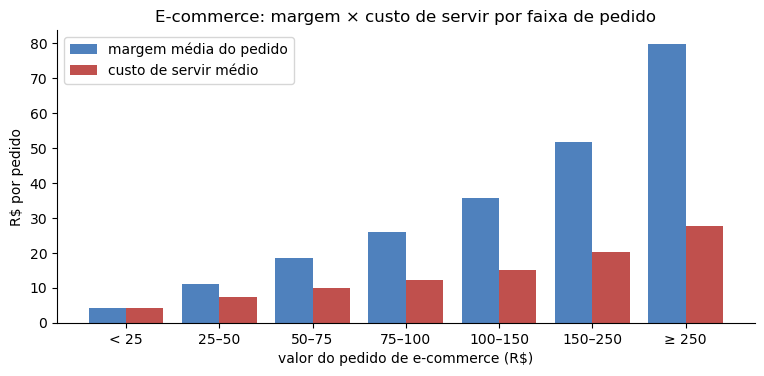

In [9]:
# Barras agrupadas por faixa (margem x custo) com o ponto de equilíbrio visível onde a margem passa o custo.
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(fx))
ax.bar(x - 0.2, fx.margem_media, 0.4, label="margem média do pedido", color="#4F81BD")
ax.bar(x + 0.2, fx.custo_medio, 0.4, label="custo de servir médio", color="#C0504D")
ax.set_xticks(x, fx.index.astype(str)); ax.set_xlabel("valor do pedido de e-commerce (R$)"); ax.set_ylabel("R$ por pedido")
ax.set_title("E-commerce: margem × custo de servir por faixa de pedido"); ax.legend()
savefig(fig, "10c_ecommerce_equilibrio", out=PH10)

## 6. Rentabilidade por SKU

In [10]:
gs = lin.groupby("sku_id").agg(linhas=("order_line_id", "size"), receita=("receita", "sum"), margem=("margem", "sum"),
                               custo=("custo", "sum"), custo_m=("custo_mercado", "sum"))
sk = sku[["sku_code", "description", "category", "zone", "status", "und_exp", "custo_sku"]].join(gs, how="left").fillna(0)
sk.loc[sk.und_exp == 0, ["custo", "custo_m"]] = sk.loc[sk.und_exp == 0, "custo_sku"]   # parado: custo sem venda
sk.loc[sk.und_exp == 0, "custo_m"] = sku.loc[sk.und_exp == 0, "custo_sku_mercado"]
sk["contrib"] = sk.margem - sk.custo
sk["contrib_mercado"] = sk.margem - sk.custo_m
abc = pd.read_csv(ROOT / "reports" / "phase4" / "sku_abc_xyz.csv", sep=";", decimal=",").set_index("sku_id")
sk["abc"] = abc.abc
save(sk.reset_index().round(2), "10c_rentabilidade_sku", out=PH10)

res_sku = sk.groupby("zone").agg(skus=("linhas", "size"), receita=("receita", "sum"), margem=("margem", "sum"),
                                  custo=("custo", "sum"), contrib=("contrib", "sum"), contrib_m=("contrib_mercado", "sum"))
res_sku["neg_dados"] = sk.groupby("zone").contrib.apply(lambda s: (s < 0).sum())
res_sku["neg_mercado"] = sk.groupby("zone").contrib_mercado.apply(lambda s: (s < 0).sum())
for c in ["receita", "margem", "custo", "contrib", "contrib_m"]:
    res_sku[c] = res_sku[c] * K / 1e6
res_sku.round(1)

,skus,receita,margem,custo,contrib,contrib_m,neg_dados,neg_mercado
zone,,,,,,,,
chilled,90,947.20,279.90,31.60,248.40,261.60,1,1
dry,450,"1,401.20",430.50,26.30,404.20,404.20,25,25
frozen,60,413.90,124.10,38.80,85.30,114.50,0,0


In [11]:
# SKUs que destroem valor na visão de mercado (a conservadora): os 10 piores, com o motivo dominante
piores = sk.sort_values("contrib_mercado").head(10).copy()
custo_frac = sku.loc[piores.index, COL_SKU].div(sku.loc[piores.index, "custo_sku"], axis=0)
piores["maior_custo"] = custo_frac.idxmax(axis=1).str.replace("c_", "")
piores[["sku_code", "category", "zone", "abc", "status", "receita", "margem", "custo_m", "contrib_mercado", "maior_custo"]].round(0)

,sku_code,category,zone,abc,status,receita,margem,custo_m,contrib_mercado,maior_custo
sku_id,,,,,,,,,,
172,SKU000173,Mercearia,dry,B,DISCONTINUED,0.00,0.00,"29,059.00","-29,059.00",perdas
1,SKU000002,Mercearia,dry,C,DISCONTINUED,0.00,0.00,"8,984.00","-8,984.00",perdas
282,SKU000283,Higiene e Limpeza,dry,C,DISCONTINUED,0.00,0.00,"4,767.00","-4,767.00",perdas
339,SKU000340,Higiene e Limpeza,dry,C,DISCONTINUED,0.00,0.00,"2,421.00","-2,421.00",aluguel
98,SKU000099,Bebidas,dry,C,DISCONTINUED,0.00,0.00,"2,329.00","-2,329.00",perdas
467,SKU000468,Laticínios,chilled,C,ACTIVE,"4,343.00","1,281.00","2,935.00","-1,653.00",perdas
223,SKU000224,Mercearia,dry,C,DISCONTINUED,0.00,0.00,"1,651.00","-1,651.00",perdas
217,SKU000218,Matinais e Cereais,dry,C,DISCONTINUED,0.00,0.00,"1,602.00","-1,602.00",perdas
135,SKU000136,Higiene e Limpeza,dry,C,DISCONTINUED,0.00,0.00,"1,596.00","-1,596.00",aluguel


abc,A,B,C
zone,,,
dry,306.27,72.71,25.26
chilled,238.15,20.33,3.09
frozen,98.43,13.25,2.84


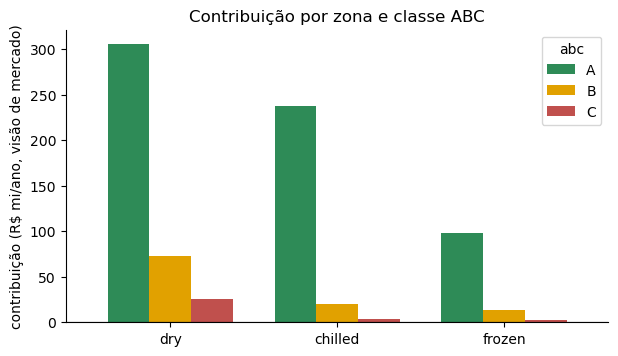

In [12]:
# Barras empilhadas por zona e classe ABC: contribuição na visão de mercado (onde o valor nasce e onde some).
tab = sk.pivot_table(index="zone", columns="abc", values="contrib_mercado", aggfunc="sum").reindex(ZONAS) * K / 1e6
fig, ax = plt.subplots(figsize=(7, 3.8))
tab.plot.bar(ax=ax, color=["#2E8B57", "#E1A100", "#C0504D"], width=0.75)
ax.axhline(0, color="black", lw=0.8); ax.set_ylabel("contribuição (R$ mi/ano, visão de mercado)")
ax.set_xlabel(""); ax.set_title("Contribuição por zona e classe ABC"); ax.tick_params(axis="x", rotation=0)
savefig(fig, "10c_contribuicao_zona_abc", out=PH10)
tab.round(2)

## 7. Leitura e ações (5W2H)
- **Clientes:** com a margem do cadastro, todos pagam o custo do CD. O indicador útil é o **custo de servir
  em % da receita**: ~3,4% na loja e ~17% no cliente de e-commerce.
- **E-commerce:** pedidos **abaixo de R$ 25** (cerca de 1 em cada 4) empatam: a margem mal cobre a
  separação e a embalagem, e metade deles dá prejuízo. A alavanca é comercial: **pedido mínimo ou frete
  por faixa**, decisão da diretoria comercial. O carrinho em lote (I04) baixa o custo e desloca o equilíbrio.
- **SKUs:** 26 dos 600 SKUs têm contribuição negativa (−R$ ~0,6 mi/ano em escala cheia), **todos curva C**.
  Dois grupos: (1) **descontinuados parados** no seco, que concentram a maior parte do valor negativo: não
  vendem e continuam pagando aluguel, capital e baixas (é o estoque morto da Fase 4, agora em R$); (2) itens
  **ativos de giro baixo** do seco (bebidas, higiene), com muito palete-dia para pouca venda, e um laticínio
  com perda alta. Ação: liquidar na descontinuação e rever mix e lote de compra com Compras.
- **Onde nasce o valor:** os itens A de cada zona geram a maior parte da contribuição. No congelado, a visão
  de dados reduz muito a contribuição por causa da perda de frio, outra vez o I01.

| O quê | Por quê | Quem | Quando | Como | Quanto |
|---|---|---|---|---|---|
| Propor pedido mínimo ou frete por faixa no e-commerce | Pedidos abaixo do equilíbrio não pagam o custo | Comercial + Controladoria | Onda 2 | Faixas da seção 5; teste A/B em uma região | Zero (política) |
| Revisão de mix dos SKUs de contribuição negativa | Custo de armazenagem e perda maior que a margem | Compras + Comercial | Trimestral | Lista `10c_rentabilidade_sku.csv` | Zero |
| Custo de servir no painel mensal | Acompanhar cliente e SKU depois das ações | Controladoria | Onda 1 | Power BI com as tabelas desta fase | Zero |

In [13]:
log(NB, f"custo de servir por cliente e SKU (ABC: linhas, palete-dia, valor em estoque, paletes recebidos, "
        f"reabastecimentos, baixas diretas por SKU); fecha com a Fase 8; valores por entidade em escala dos dados, totais x{K}")